# EDA — Adult (Parte Específica)

Análise exploratória dos quatro pilares: **estrutura**, **distribuições**, **relações com a classe** e **outliers**.
Classe-alvo: `income` (`<=50K` ou `>50K`). Execute `python src/parte_especifica/download_data.py` antes, para gerar `data/parte_especifica/adult.csv`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PALETA = {"<=50K": "#4C78A8", ">50K": "#E45756"}
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG = ROOT / "out" / "parte_especifica" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

df = pd.read_csv(ROOT / "data" / "parte_especifica" / "adult.csv")
NUM = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CAT = [c for c in df.columns if c not in NUM + ["income"]]
df["alta_renda"] = (df["income"] == ">50K").astype(int)
df.shape

(48842, 16)

## 1. Estrutura e valores ausentes

In [2]:
df.drop(columns="alta_renda").dtypes.to_frame("tipo").T

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
tipo,int64,str,int64,str,int64,str,str,str,str,str,int64,int64,int64,str,str


In [3]:
aus = df.drop(columns="alta_renda").isna().sum()
aus = aus[aus > 0].rename("ausentes").to_frame()
aus["percentual"] = (aus["ausentes"] / len(df) * 100).round(2)
print("Linhas com ao menos um ausente:", df.isna().any(axis=1).sum(), f"({df.isna().any(axis=1).mean():.2%})")
print("Duplicatas exatas:", df.drop(columns='alta_renda').duplicated().sum())
aus

Linhas com ao menos um ausente: 3620 (7.41%)
Duplicatas exatas: 52


,ausentes,percentual
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


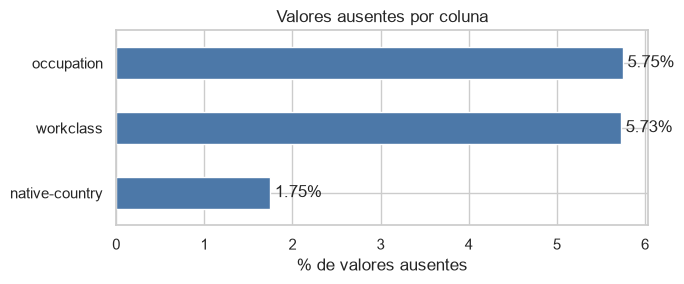

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
aus["percentual"].sort_values().plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("% de valores ausentes"); ax.set_ylabel("")
ax.set_title("Valores ausentes por coluna")
for i, v in enumerate(aus["percentual"].sort_values()):
    ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
salvar("01_ausentes")

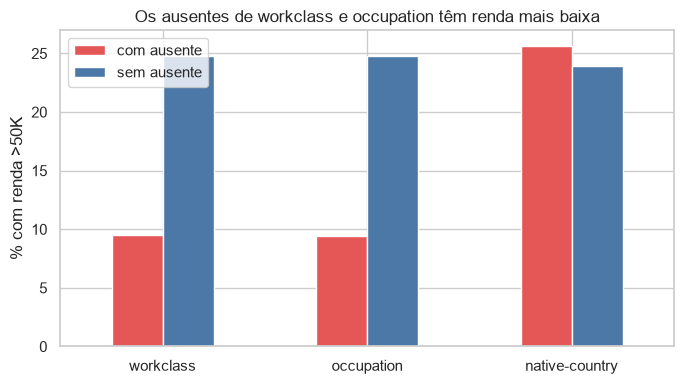

In [5]:
taxa = pd.DataFrame({
    "com ausente": [df.loc[df[c].isna(), "alta_renda"].mean() for c in aus.index],
    "sem ausente": [df.loc[df[c].notna(), "alta_renda"].mean() for c in aus.index],
}, index=aus.index)
ax = (taxa * 100).plot.bar(figsize=(7, 4), color=["#E45756", "#4C78A8"], rot=0)
ax.set_ylabel("% com renda >50K"); ax.set_title("Os ausentes de workclass e occupation têm renda mais baixa")
salvar("02_ausentes_vs_renda")

## 2. Distribuições

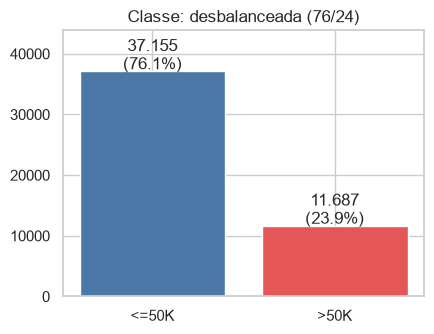

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 3.5))
cont = df["income"].value_counts()
ax.bar(cont.index, cont.values, color=[PALETA[i] for i in cont.index])
for i, v in enumerate(cont.values):
    ax.text(i, v + 300, f"{v:,}\n({v/len(df):.1%})".replace(",", "."), ha="center")
ax.set_ylim(0, cont.max() * 1.18); ax.set_title("Classe: desbalanceada (76/24)")
salvar("03_classe")

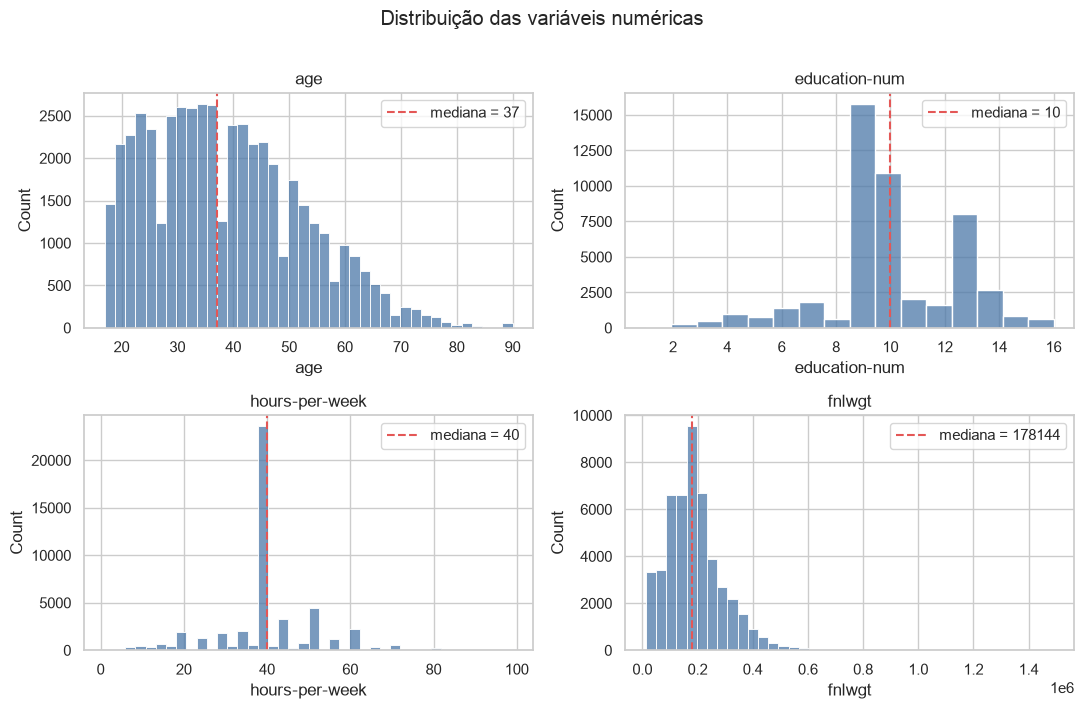

In [7]:
vars_hist = ["age", "education-num", "hours-per-week", "fnlwgt"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(axes.ravel(), vars_hist):
    sns.histplot(df[v], bins=40 if v != "education-num" else 16, color="#4C78A8", ax=ax)
    ax.axvline(df[v].median(), color="#E45756", ls="--", label=f"mediana = {df[v].median():.0f}")
    ax.legend(); ax.set_title(v)
fig.suptitle("Distribuição das variáveis numéricas", y=1.01)
salvar("04_histogramas")

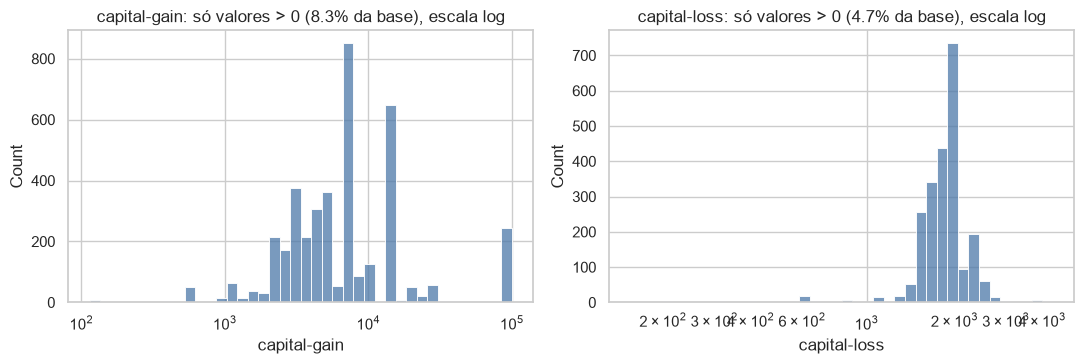

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, v in zip(axes, ["capital-gain", "capital-loss"]):
    pos = df.loc[df[v] > 0, v]
    sns.histplot(pos, bins=40, log_scale=True, color="#4C78A8", ax=ax)
    ax.set_title(f"{v}: só valores > 0 ({len(pos)/len(df):.1%} da base), escala log")
salvar("05_capital")

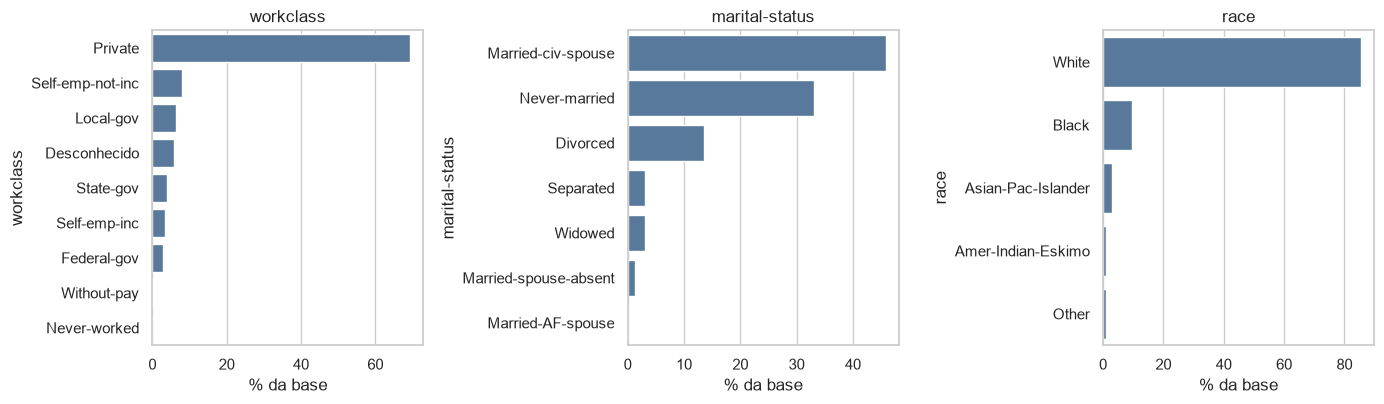

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, v in zip(axes, ["workclass", "marital-status", "race"]):
    ordem = df[v].fillna("Desconhecido").value_counts()
    sns.barplot(x=ordem.values / len(df) * 100, y=ordem.index, color="#4C78A8", ax=ax)
    ax.set_xlabel("% da base"); ax.set_title(v)
salvar("06_categoricas")

## 3. Relações com a classe

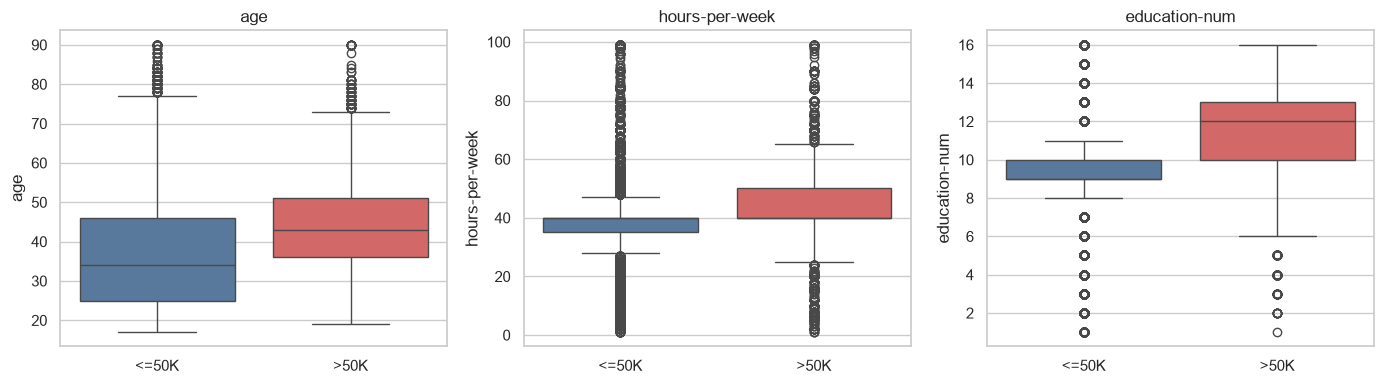

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(axes, ["age", "hours-per-week", "education-num"]):
    sns.boxplot(data=df, x="income", y=v, hue="income", palette=PALETA, legend=False, ax=ax, order=["<=50K", ">50K"])
    ax.set_title(v); ax.set_xlabel("")
salvar("07_boxplots_por_classe")

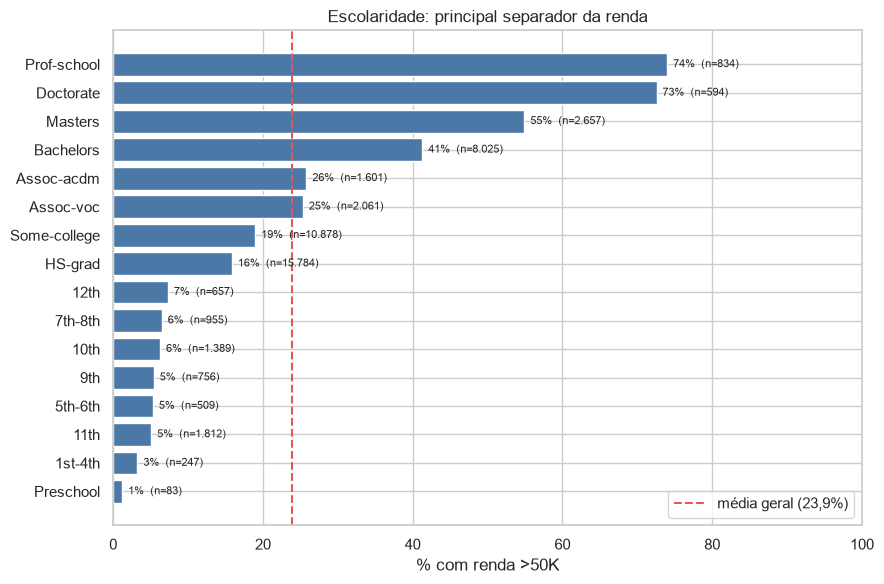

In [11]:
def taxa_por(coluna, ordenar=True, minimo=0):
    t = (df.assign(**{coluna: df[coluna].fillna("Desconhecido")})
           .groupby(coluna)["alta_renda"].agg(["mean", "size"]))
    t = t[t["size"] >= minimo]
    return t.sort_values("mean") if ordenar else t

def barras_taxa(coluna, ax, titulo=None):
    t = taxa_por(coluna)
    ax.barh(t.index, t["mean"] * 100, color="#4C78A8")
    ax.axvline(df["alta_renda"].mean() * 100, color="#E45756", ls="--", label="média geral (23,9%)")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(m * 100 + 0.8, i, f"{m:.0%}  (n={n:,})".replace(",", "."), va="center", fontsize=8)
    ax.set_xlim(0, 100); ax.set_xlabel("% com renda >50K"); ax.set_title(titulo or coluna); ax.legend(loc="lower right")

fig, ax = plt.subplots(figsize=(9, 6))
barras_taxa("education", ax, "Escolaridade: principal separador da renda")
salvar("08_renda_por_escolaridade")

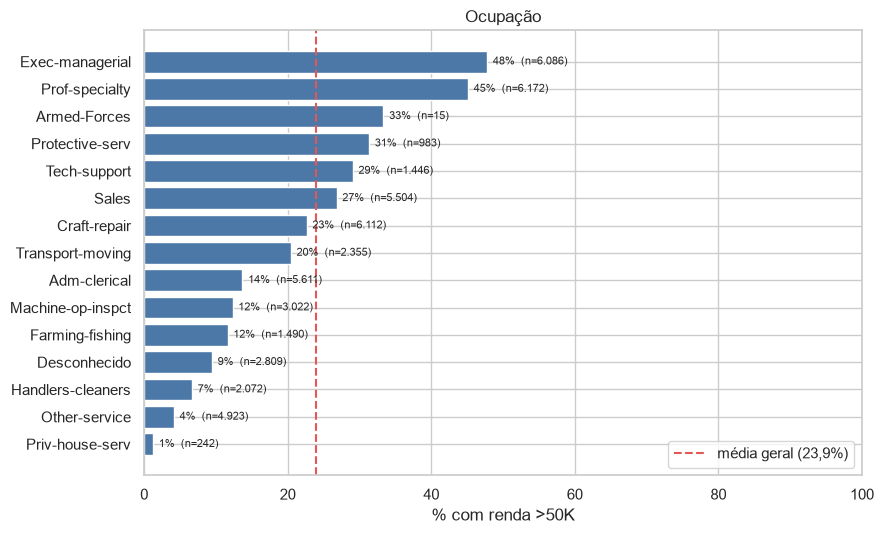

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
barras_taxa("occupation", ax, "Ocupação")
salvar("09_renda_por_ocupacao")

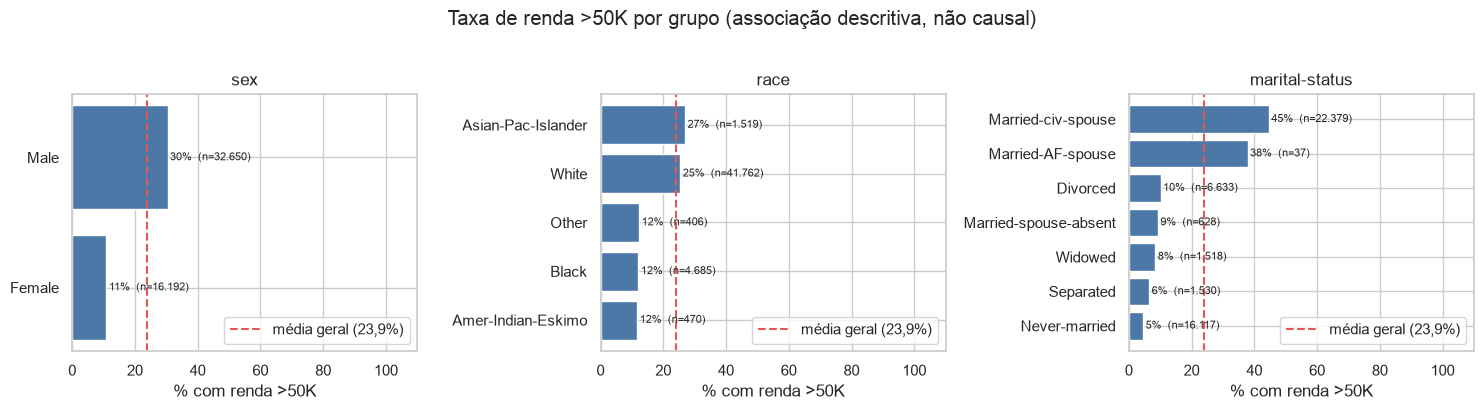

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, v in zip(axes, ["sex", "race", "marital-status"]):
    barras_taxa(v, ax)
    ax.set_xlim(0, 110)
fig.suptitle("Taxa de renda >50K por grupo (associação descritiva, não causal)", y=1.02)
salvar("10_renda_por_sexo_raca_estado_civil")

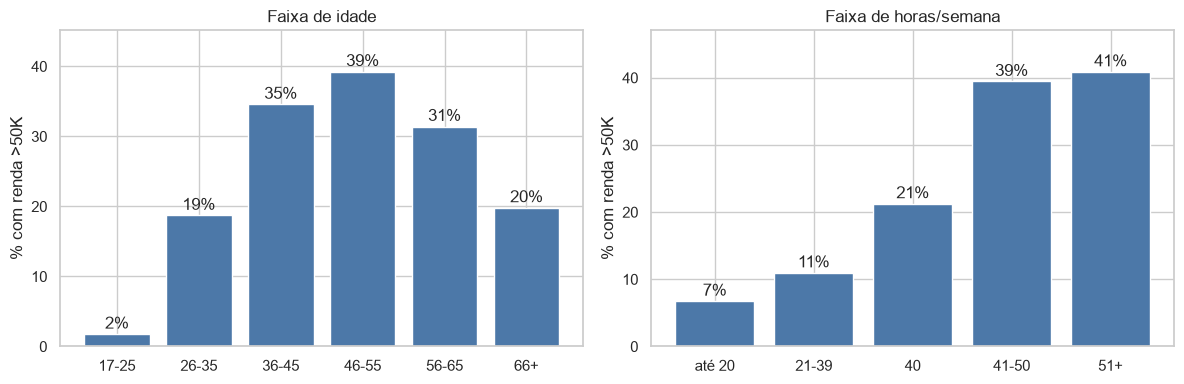

In [14]:
df["faixa_idade"] = pd.cut(df["age"], [16, 25, 35, 45, 55, 65, 91], labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"])
df["faixa_horas"] = pd.cut(df["hours-per-week"], [0, 20, 39, 40, 50, 99], labels=["até 20", "21-39", "40", "41-50", "51+"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, ["faixa_idade", "faixa_horas"]):
    t = df.groupby(v, observed=True)["alta_renda"].mean() * 100
    ax.bar(t.index.astype(str), t.values, color="#4C78A8")
    ax.set_ylim(0, t.max() * 1.15)
    for i, x in enumerate(t.values): ax.text(i, x + 0.8, f"{x:.0f}%", ha="center")
    ax.set_ylabel("% com renda >50K"); ax.set_title(v.replace("faixa_", "Faixa de ").replace("idade", "idade").replace("horas", "horas/semana"))
salvar("11_renda_por_faixas")

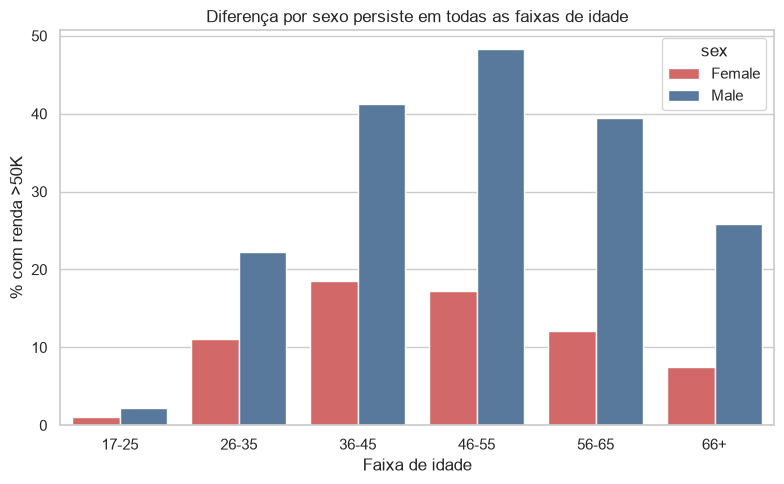

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
sex_idade = df.groupby(["faixa_idade", "sex"], observed=True)["alta_renda"].mean().mul(100).reset_index()
sns.barplot(data=sex_idade, x="faixa_idade", y="alta_renda", hue="sex", palette=["#E45756", "#4C78A8"], ax=ax)
ax.set_ylabel("% com renda >50K"); ax.set_xlabel("Faixa de idade"); ax.set_title("Diferença por sexo persiste em todas as faixas de idade")
salvar("12_sexo_por_idade")

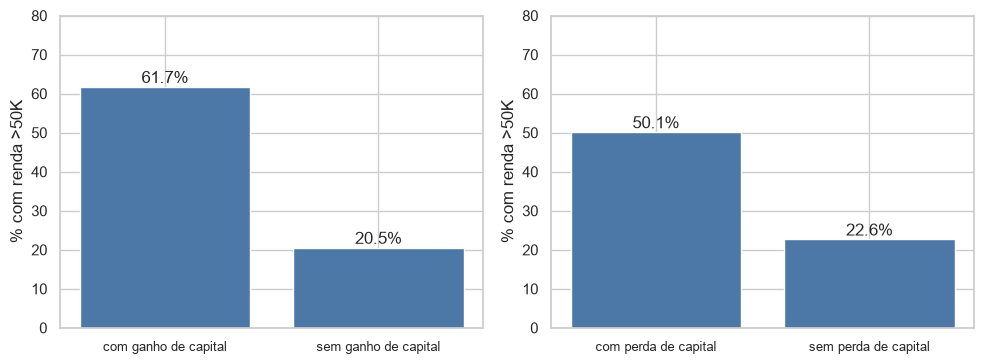

In [16]:
df["tem_ganho"] = np.where(df["capital-gain"] > 0, "com ganho de capital", "sem ganho de capital")
df["tem_perda"] = np.where(df["capital-loss"] > 0, "com perda de capital", "sem perda de capital")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, v in zip(axes, ["tem_ganho", "tem_perda"]):
    t = df.groupby(v)["alta_renda"].mean() * 100
    ax.bar(t.index, t.values, color="#4C78A8"); ax.set_ylim(0, 80)
    for i, x in enumerate(t.values): ax.text(i, x + 1, f"{x:.1f}%", ha="center")
    ax.set_ylabel("% com renda >50K"); ax.tick_params(axis="x", labelsize=9)
salvar("13_capital_vs_renda")

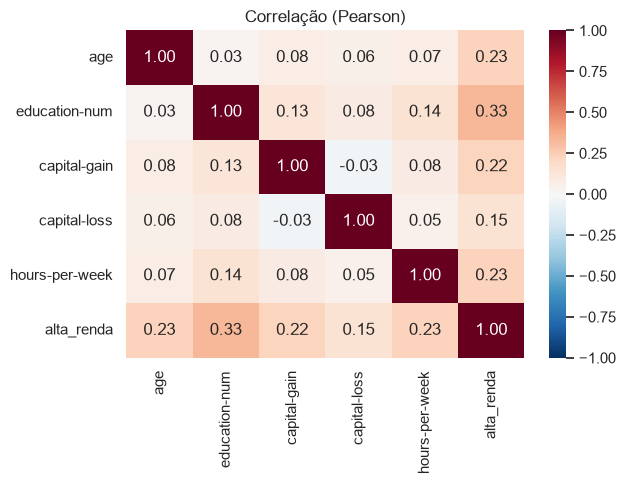

In [17]:
corr = df[["age", "education-num", "capital-gain", "capital-loss", "hours-per-week", "alta_renda"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação (Pearson)")
salvar("14_correlacao")

## 4. Outliers (critério do IQR)

In [18]:
linhas = []
for v in NUM:
    q1, q3 = df[v].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[v] < lo) | (df[v] > hi)).sum()
    linhas.append((v, q1, q3, lo, hi, n, round(n / len(df) * 100, 2)))
out = pd.DataFrame(linhas, columns=["variavel", "Q1", "Q3", "limite_inf", "limite_sup", "candidatos", "%"]).set_index("variavel")
out

,Q1,Q3,limite_inf,limite_sup,candidatos,%
variavel,,,,,,
age,28.0,48.0,-2.00,78.00,216,0.44
fnlwgt,117550.5,237642.0,-62586.75,417779.25,1453,2.97
education-num,9.0,12.0,4.50,16.50,1794,3.67
capital-gain,0.0,0.0,0.00,0.00,4035,8.26
capital-loss,0.0,0.0,0.00,0.00,2282,4.67
hours-per-week,40.0,45.0,32.50,52.50,13496,27.63


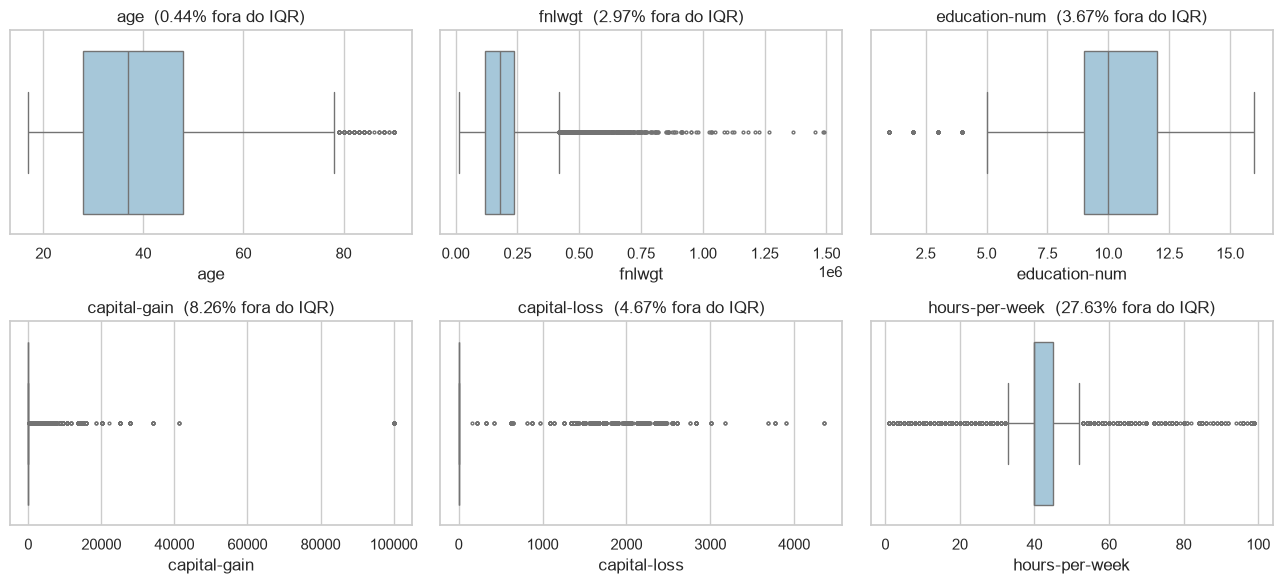

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, v in zip(axes.ravel(), NUM):
    sns.boxplot(x=df[v], color="#9ecae1", ax=ax, fliersize=2)
    ax.set_title(f"{v}  ({out.loc[v, '%']}% fora do IQR)")
salvar("15_outliers_boxplots")

In [20]:
print("capital-gain == 99999:", (df["capital-gain"] == 99999).sum(), "| todos >50K:", df.loc[df["capital-gain"] == 99999, "alta_renda"].mean() == 1)
print("age >= 80:", (df["age"] >= 80).sum(), "| hours <= 10:", (df["hours-per-week"] <= 10).sum(), "| hours >= 80:", (df["hours-per-week"] >= 80).sum())
print("hours == 40:", f"{(df['hours-per-week'] == 40).mean():.1%}")

capital-gain == 99999: 244 | todos >50K: True
age >= 80: 186 | hours <= 10: 1125 | hours >= 80: 528
hours == 40: 46.7%


### Decisões

- **Ausentes:** `workclass`, `occupation` e `native-country` são recodificados como "Desconhecido"; nenhuma linha é removida. Os ausentes de `workclass`/`occupation` têm renda mais baixa e carregam informação.
- **Outliers:** todos os registros são mantidos. Em `capital-gain`/`capital-loss`, Q1 = Q3 = 0 e o IQR vira zero; em `hours-per-week` a concentração em 40 horas estreita a faixa. 99.999 em `capital-gain` é um código de teto. `fnlwgt` é peso amostral e não é usado como variável explicativa.
- As interpretações completas estão em `docs/relatorio_template.md`.